In [ ]:
import requests
import json

weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Asia/Karachi",
}

r = requests.get(weather_url, params=weather_params)
print("Status:", r.status_code)

data = r.json()
print(data.keys())
print(json.dumps(data, indent=2)[:1500])


Status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
{
  "latitude": 31.528997,
  "longitude": 74.38995,
  "generationtime_ms": 0.05137920379638672,
  "utc_offset_seconds": 18000,
  "timezone": "Asia/Karachi",
  "timezone_abbreviation": "GMT+5",
  "elevation": 222.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%"
  },
  "hourly": {
    "time": [
      "2026-11-04T00:00",
      "2026-11-04T01:00",
      "2026-11-04T02:00",
      "2026-11-04T03:00",
      "2026-11-04T04:00",
      "2026-11-04T05:00",
      "2026-11-04T06:00",
      "2026-11-04T07:00",
      "2026-11-04T08:00",
      "2026-11-04T09:00",
      "2026-11-04T10:00",
      "2026-11-04T11:00",
      "2026-11-04T12:00",
      "2026-11-04T13:00",
      "2026-11-04T14:00",
      "2026-11-04T15:00",
      "2026-11-04T16:00",
      "2026-11-04T17:00",
      "2

In [ ]:
df = hist.copy()

# missing values hatao
df = df.dropna()

# naye columns (features)
df["hour"] = df["time"].dt.hour
df["aqi_lag1"] = df["us_aqi"].shift(1)      # pichle ghante ka AQI
df["pm25_lag1"] = df["pm2_5"].shift(1)      # pichle ghante ka PM2.5
df["target"] = df["us_aqi"].shift(-1)       # agle ghante ka AQI (jo predict karna hai)

df = df.dropna()
print(df.shape)
print(df.head())

(820, 8)
                 time  pm10  pm2_5  us_aqi  hour  aqi_lag1  pm25_lag1  target
1 2026-10-05 01:00:00  76.8   67.1   162.0     1     163.0       67.3   161.0
2 2026-10-05 02:00:00  77.3   67.5   161.0     2     162.0       67.1   160.0
3 2026-10-05 03:00:00  78.2   68.2   160.0     3     161.0       67.5   159.0
4 2026-10-05 04:00:00  79.4   68.9   159.0     4     160.0       68.2   158.0
5 2026-10-05 05:00:00  81.0   69.8   158.0     5     159.0       68.9   157.0


In [ ]:
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 30,
    "timezone": "Asia/Karachi",
}

r = requests.get(url, params=params)
print("Status:", r.status_code)

hist = pd.DataFrame(r.json()["hourly"])
hist["time"] = pd.to_datetime(hist["time"])
print(hist.shape)
print(hist.describe())


Status: 200
(840, 4)
                                time        pm10       pm2_5      us_aqi
count                            840  822.000000  822.000000  823.000000
mean   2026-10-22 11:30:00.000000256   88.039538   71.149392  156.839611
min              2026-10-05 00:00:00   10.500000    9.300000   80.000000
25%              2026-10-13 17:45:00   56.300000   44.400000  144.000000
50%              2026-10-22 11:30:00   80.000000   64.300000  157.000000
75%              2026-10-31 05:15:00  111.175000   91.225000  171.000000
max              2026-11-08 23:00:00  292.400000  186.700000  215.000000
std                              NaN   43.995025   36.216705   25.459735


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

features = ["hour", "pm2_5", "pm10", "aqi_lag1", "pm25_lag1"]
X = df[features]
y = df["target"]

# time order mein baanto (shuffle nahi)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, pred))

MAE: 2.458982790241517


In [ ]:
baseline_pred = X_test["aqi_lag1"]
print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))

Baseline MAE: 2.1890243902439024


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest MAE: 5.940914634146342


In [ ]:
import pandas as pd

aq_url = "https://air-quality-api.open-meteo.com/v1/air-quality"
aq_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "timezone": "Asia/Karachi",
}

r = requests.get(aq_url, params=aq_params)
print("Status:", r.status_code)

aq = r.json()
aq_df = pd.DataFrame(aq["hourly"])
aq_df["time"] = pd.to_datetime(aq_df["time"])
print(aq_df.head())
print(aq_df.shape)

Status: 200
                 time   pm10  pm2_5  us_aqi
0 2026-11-04 00:00:00  139.2  130.4   189.0
1 2026-11-04 01:00:00  141.1  132.2   188.0
2 2026-11-04 02:00:00  142.5  133.6   188.0
3 2026-11-04 03:00:00  143.0  134.6   187.0
4 2026-11-04 04:00:00  142.5  134.6   187.0
(120, 4)


In [ ]:
y_train_d = y_train - X_train["aqi_lag1"]

rf2 = RandomForestRegressor(n_estimators=100, random_state=42)
rf2.fit(X_train, y_train_d)

rf2_pred = rf2.predict(X_test) + X_test["aqi_lag1"]
print("RF (change) MAE:", mean_absolute_error(y_test, rf2_pred))

RF (change) MAE: 4.8861585365853655


In [ ]:
print(data["hourly"].keys())
print(data["hourly"]["time"][0])
print(data["hourly"]["temperature_2m"][0])


dict_keys(['time', 'temperature_2m', 'relative_humidity_2m'])
2026-11-04T00:00
20.0


In [ ]:

print(data["hourly"]["time"][1])
print(data["hourly"]["temperature_2m"][1])
print(len(data["hourly"]["time"]))


2026-11-04T01:00
19.6
168


In [ ]:
import pandas as pd

df = pd.DataFrame(data["hourly"])
print(df.head())
print(df.shape)


               time  temperature_2m  relative_humidity_2m
0  2026-11-04T00:00            20.0                    78
1  2026-11-04T01:00            19.6                    80
2  2026-11-04T02:00            19.3                    81
3  2026-11-04T03:00            19.0                    83
4  2026-11-04T04:00            18.7                    85
(168, 3)


In [ ]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)
print(df["temperature_2m"].max(), df["temperature_2m"].min())

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
dtype: object
29.1 16.1


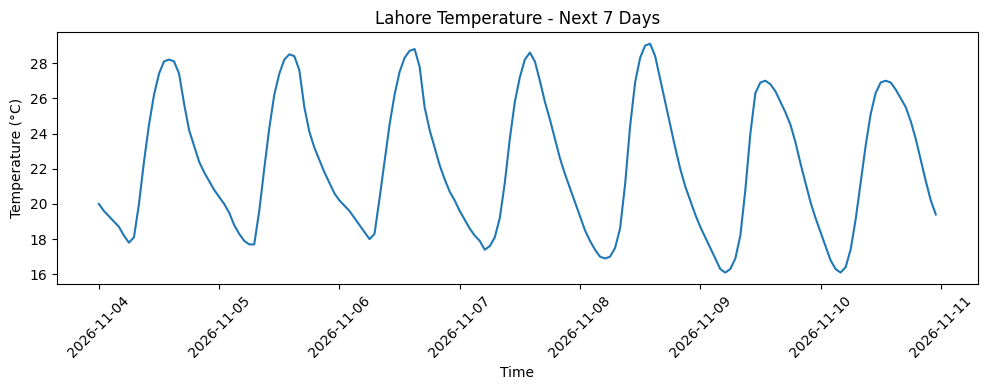

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["temperature_2m"])
plt.title("Lahore Temperature - Next 7 Days")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

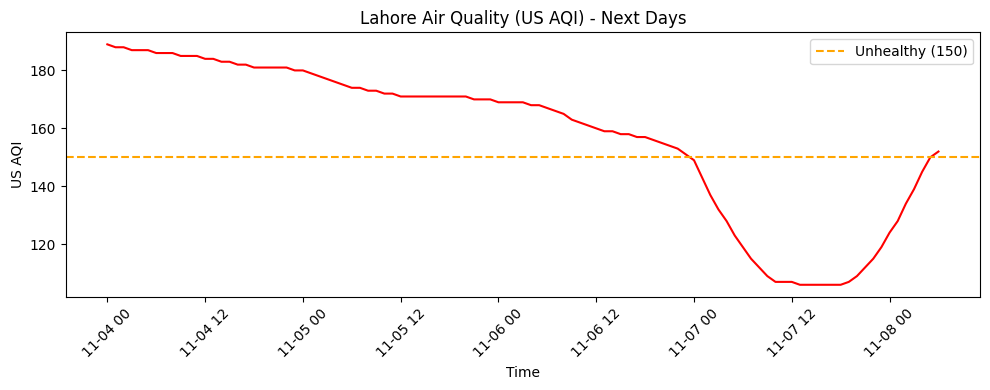

Max AQI: 189.0
Average AQI: 157.33009708737865


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(aq_df["time"], aq_df["us_aqi"], color="red")
plt.axhline(150, color="orange", linestyle="--", label="Unhealthy (150)")
plt.title("Lahore Air Quality (US AQI) - Next Days")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Max AQI:", aq_df["us_aqi"].max())
print("Average AQI:", aq_df["us_aqi"].mean())